# ১. গবেষণার বর্তমান ধাপ — Dataset থেকে Best Model পর্যন্ত

**আজকের কাজের সীমা:** আমরা এখন research workflow-এর প্রথম অংশ implement করছি।

**Workflow:**  
`Dataset → Data Understanding → EDA → Data Cleaning → Feature Categorization → Train/Holdout Split → Preprocessing Pipeline → Baseline Model → Model Validation → Best Model`

**কেন এই অংশ আগে?**  
আমাদের মূল research contribution পরে আসবে **domain-level ablation + SHAP + counterfactual analysis**-এ। তার আগে একটি leakage-controlled, reproducible baseline দরকার। Source paper-এ 1,100 observations, 20 predictors এবং `stress_level` target ব্যবহার করা হয়েছে; dataset-টি পাঁচটি conceptual domain-এ ভাগ করা হয়েছে। fileciteturn2file3L149-L164

> **গুরুত্বপূর্ণ:** এই notebook এখনো কোনো result আগে থেকে ধরে নিচ্ছে না। Model run করার পরেই কোন model best তা নির্ধারিত হবে।

# ২. প্রয়োজনীয় লাইব্রেরি ইনস্টল/ইমপোর্ট

**এই cell-এ কী হচ্ছে?**  
Research-এর জন্য প্রয়োজনীয় Python libraries import করা হচ্ছে।

**কেন করছি?**  
Data handling, visualization, preprocessing, cross-validation এবং model evaluation—সবকিছুর জন্য এগুলো প্রয়োজন।

**Research principle:** সব random process-এর জন্য `random_state=42` রাখব, যাতে পরে একই experiment আবার চালানো যায়। Source paper-ও reproducibility-এর জন্য fixed random seeds ব্যবহারের কথা জানিয়েছে। fileciteturn1file7L364-L370

In [1]:
# প্রয়োজনীয় লাইব্রেরি
import os
import glob
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    precision_score, recall_score, matthews_corrcoef,
    classification_report, confusion_matrix
)

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier, ExtraTreesClassifier,
    GradientBoostingClassifier, HistGradientBoostingClassifier,
    AdaBoostClassifier
)

RANDOM_STATE = 42
TARGET = "stress_level"

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

print("Libraries loaded successfully.")

Libraries loaded successfully.


#For_KAGGLE

In [2]:
# # ডেটাসেট লোড
# df = pd.read_csv('/kaggle/input/datasets/romim86/stressleveldatasetlab/StressLevelDataset.csv')
# X = df.drop('stress_level', axis=1)
# y = df['stress_level']

# ৩. Dataset খুঁজে লোড করা

**এই cell-এ কী হচ্ছে?**  
Current folder এবং common `data/` folder-এর মধ্যে CSV/Excel dataset খুঁজে বের করার চেষ্টা করবে।

**কেন করছি?**  
Notebook-এ dataset path hard-code করে দিলে অন্য computer-এ notebook চালাতে সমস্যা হতে পারে। তাই প্রথমে automatic detection রাখা হয়েছে।

**তোমার কাজ:**  
যদি automatic detection dataset না পায়, নিচের `DATA_PATH` variable-এ তোমার CSV file-এর path বসাবে।

Source paper অনুযায়ী dataset হলো Kaggle-এর **Student Stress Factors** dataset, যেখানে 1,100 students এবং 20 predictors + 1 target আছে। fileciteturn1file7L373-L388

In [3]:
# Dataset path
DATA_PATH = None
# উদাহরণ:
# DATA_PATH = "Student Stress Factors.csv"

def find_candidate_files():
    patterns = [
        "*.csv", "*.CSV",
        "*.xlsx", "*.XLSX"
    ]
    candidates = []
    search_dirs = [".", "./data", "./dataset", "./datasets"]
    for folder in search_dirs:
        for pattern in patterns:
            candidates.extend(glob.glob(os.path.join(folder, pattern)))
    return sorted(set(candidates))

if DATA_PATH is None:
    candidates = find_candidate_files()
    if not candidates:
        raise FileNotFoundError(
            "Dataset পাওয়া যায়নি। DATA_PATH variable-এ CSV/XLSX file-এর path বসাও।"
        )
    print("Candidate files:")
    for i, f in enumerate(candidates, 1):
        print(f"{i}. {f}")
    DATA_PATH = candidates[0]
    print("\nSelected:", DATA_PATH)

if DATA_PATH.lower().endswith(".csv"):
    df = pd.read_csv(DATA_PATH)
elif DATA_PATH.lower().endswith((".xlsx", ".xls")):
    df = pd.read_excel(DATA_PATH)
else:
    raise ValueError("CSV বা Excel dataset প্রয়োজন।")

print("Dataset loaded:", df.shape)
df.head()

Candidate files:
1. .\StressLevelDataset.csv

Selected: .\StressLevelDataset.csv
Dataset loaded: (1100, 21)


,anxiety_level,self_esteem,mental_health_history,depression,headache,blood_pressure,sleep_quality,breathing_problem,noise_level,living_conditions,safety,basic_needs,academic_performance,study_load,teacher_student_relationship,future_career_concerns,social_support,peer_pressure,extracurricular_activities,bullying,stress_level
0,14,20,0,11,2,1,2,4,2,3,3,2,3,2,3,3,2,3,3,2,1
1,15,8,1,15,5,3,1,4,3,1,2,2,1,4,1,5,1,4,5,5,2
2,12,18,1,14,2,1,2,2,2,2,3,2,2,3,3,2,2,3,2,2,1
3,16,12,1,15,4,3,1,3,4,2,2,2,2,4,1,4,1,4,4,5,2
4,16,28,0,7,2,3,5,1,3,2,4,3,4,3,1,2,1,5,0,5,1


# ৪. Data Understanding — Dataset-এর গঠন বোঝা

**এই cell-এ কী হচ্ছে?**  
Dataset-এর shape, column names, data types এবং sample rows দেখা হবে।

**কেন করছি?**  
Model বানানোর আগে আমাদের নিশ্চিত হতে হবে:
- কতটি row আছে?
- target column আছে কি?
- predictor কতটি?
- কোন feature numerical/categorical?
- column naming ঠিক আছে কি?

Source paper-এ target হিসেবে `stress_level` নির্ধারণ করা হয়েছে এবং এটিকে 3-class classification হিসেবে নেওয়া হয়েছে। fileciteturn2file0L14-L27

In [4]:
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("dtype"))

print("\nFirst 5 rows:")
display(df.head())

print("\nBasic information:")
df.info()

Shape: (1100, 21)

Columns:
['anxiety_level', 'self_esteem', 'mental_health_history', 'depression', 'headache', 'blood_pressure', 'sleep_quality', 'breathing_problem', 'noise_level', 'living_conditions', 'safety', 'basic_needs', 'academic_performance', 'study_load', 'teacher_student_relationship', 'future_career_concerns', 'social_support', 'peer_pressure', 'extracurricular_activities', 'bullying', 'stress_level']

Data types:


,dtype
anxiety_level,int64
self_esteem,int64
mental_health_history,int64
depression,int64
headache,int64
blood_pressure,int64
sleep_quality,int64
breathing_problem,int64
noise_level,int64
living_conditions,int64



First 5 rows:


,anxiety_level,self_esteem,mental_health_history,depression,headache,blood_pressure,sleep_quality,breathing_problem,noise_level,living_conditions,safety,basic_needs,academic_performance,study_load,teacher_student_relationship,future_career_concerns,social_support,peer_pressure,extracurricular_activities,bullying,stress_level
0,14,20,0,11,2,1,2,4,2,3,3,2,3,2,3,3,2,3,3,2,1
1,15,8,1,15,5,3,1,4,3,1,2,2,1,4,1,5,1,4,5,5,2
2,12,18,1,14,2,1,2,2,2,2,3,2,2,3,3,2,2,3,2,2,1
3,16,12,1,15,4,3,1,3,4,2,2,2,2,4,1,4,1,4,4,5,2
4,16,28,0,7,2,3,5,1,3,2,4,3,4,3,1,2,1,5,0,5,1



Basic information:
<class 'pandas.DataFrame'>
RangeIndex: 1100 entries, 0 to 1099
Data columns (total 21 columns):
 #   Column                        Non-Null Count  Dtype
---  ------                        --------------  -----
 0   anxiety_level                 1100 non-null   int64
 1   self_esteem                   1100 non-null   int64
 2   mental_health_history         1100 non-null   int64
 3   depression                    1100 non-null   int64
 4   headache                      1100 non-null   int64
 5   blood_pressure                1100 non-null   int64
 6   sleep_quality                 1100 non-null   int64
 7   breathing_problem             1100 non-null   int64
 8   noise_level                   1100 non-null   int64
 9   living_conditions             1100 non-null   int64
 10  safety                        1100 non-null   int64
 11  basic_needs                   1100 non-null   int64
 12  academic_performance          1100 non-null   int64
 13  study_load              

# ৫. Target Variable যাচাই

**এই cell-এ কী হচ্ছে?**  
`stress_level` target আছে কি না এবং তার class distribution দেখা হবে।

**কেন করছি?**  
এটি একটি supervised multiclass classification problem। Target-এর invalid/missing label থাকলে training-এর আগে সেটা handle করতে হবে।

Source paper-এ `stress_level`-কে low, medium, high—এই তিনটি observed stress category হিসেবে ব্যবহার করা হয়েছে; strict ordinal progression হিসেবে interpret করা হয়নি। fileciteturn2file3L175-L188

Target: stress_level

Target value counts:


,count
stress_level,
0,373
2,369
1,358



Target proportions:


,percentage
stress_level,
0,33.91
2,33.55
1,32.55


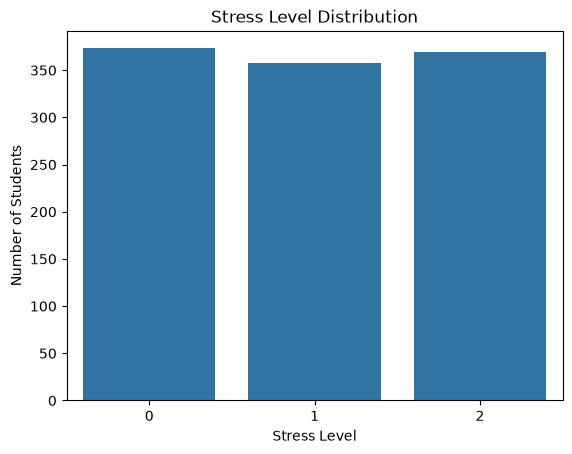

In [5]:
if TARGET not in df.columns:
    raise KeyError(
        f"'{TARGET}' column পাওয়া যায়নি। Actual target column check করো: {df.columns.tolist()}"
    )

print("Target:", TARGET)
print("\nTarget value counts:")
display(df[TARGET].value_counts(dropna=False).to_frame("count"))

print("\nTarget proportions:")
display(
    df[TARGET].value_counts(normalize=True, dropna=False)
      .mul(100).round(2).to_frame("percentage")
)

sns.countplot(data=df, x=TARGET)
plt.title("Stress Level Distribution")
plt.xlabel("Stress Level")
plt.ylabel("Number of Students")
plt.show()

# ৬. EDA — Missing Values, Duplicate এবং Unique Values

**এই cell-এ কী হচ্ছে?**  
Missing values, duplicate rows এবং প্রতিটি feature-এর unique value count বের করা হবে।

**কেন করছি?**  
Data quality problem model-এর ফলাফলকে bias করতে পারে। Source paper-এ তাদের final analytical dataset-এ predictor/target-এ missing values এবং duplicate record পাওয়া যায়নি। fileciteturn2file5L252-L267

তবে আমরা source paper-এর result copy করব না—**নিজের dataset run করে independently verify করব।**

In [6]:
missing = df.isna().sum().sort_values(ascending=False)
duplicates = df.duplicated().sum()
unique_counts = df.nunique(dropna=False).sort_values()

print("Total duplicate rows:", duplicates)

print("\nMissing values:")
display(missing.to_frame("missing_count"))

print("\nUnique values per column:")
display(unique_counts.to_frame("unique_count"))

print("\nDescriptive statistics:")
display(df.describe(include="all").T)

Total duplicate rows: 0

Missing values:


,missing_count
anxiety_level,0
self_esteem,0
mental_health_history,0
depression,0
headache,0
blood_pressure,0
sleep_quality,0
breathing_problem,0
noise_level,0
living_conditions,0



Unique values per column:


,unique_count
mental_health_history,2
blood_pressure,3
stress_level,3
social_support,4
breathing_problem,6
safety,6
headache,6
sleep_quality,6
academic_performance,6
study_load,6



Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
anxiety_level,1100.0,11.063636,6.117558,0.0,6.0,11.0,16.0,21.0
self_esteem,1100.0,17.777273,8.944599,0.0,11.0,19.0,26.0,30.0
mental_health_history,1100.0,0.492727,0.500175,0.0,0.0,0.0,1.0,1.0
depression,1100.0,12.555455,7.727008,0.0,6.0,12.0,19.0,27.0
headache,1100.0,2.508182,1.409356,0.0,1.0,3.0,3.0,5.0
blood_pressure,1100.0,2.181818,0.833575,1.0,1.0,2.0,3.0,3.0
sleep_quality,1100.0,2.660000,1.548383,0.0,1.0,2.5,4.0,5.0
breathing_problem,1100.0,2.753636,1.400713,0.0,2.0,3.0,4.0,5.0
noise_level,1100.0,2.649091,1.328127,0.0,2.0,3.0,3.0,5.0
living_conditions,1100.0,2.518182,1.119208,0.0,2.0,2.0,3.0,5.0


# ৭. EDA — Feature Distribution ও Data Pattern

**এই cell-এ কী হচ্ছে?**  
Numerical-looking columns-এর distribution এবং categorical/ordinal columns-এর frequency দেখা হবে।

**কেন করছি?**  
Dataset-এর numeric code দেখেই সব feature-কে continuous ধরে নেওয়া যাবে না। Source paper বিশেষভাবে বলেছে যে অনেক predictor numerical code হলেও semanticভাবে categorical/ordinal; তাই সেগুলোকে indiscriminately continuous হিসেবে নেওয়া উচিত নয়। fileciteturn2file0L28-L44

Numerical columns detected: ['anxiety_level', 'self_esteem', 'mental_health_history', 'depression', 'headache', 'blood_pressure', 'sleep_quality', 'breathing_problem', 'noise_level', 'living_conditions', 'safety', 'basic_needs', 'academic_performance', 'study_load', 'teacher_student_relationship', 'future_career_concerns', 'social_support', 'peer_pressure', 'extracurricular_activities', 'bullying']


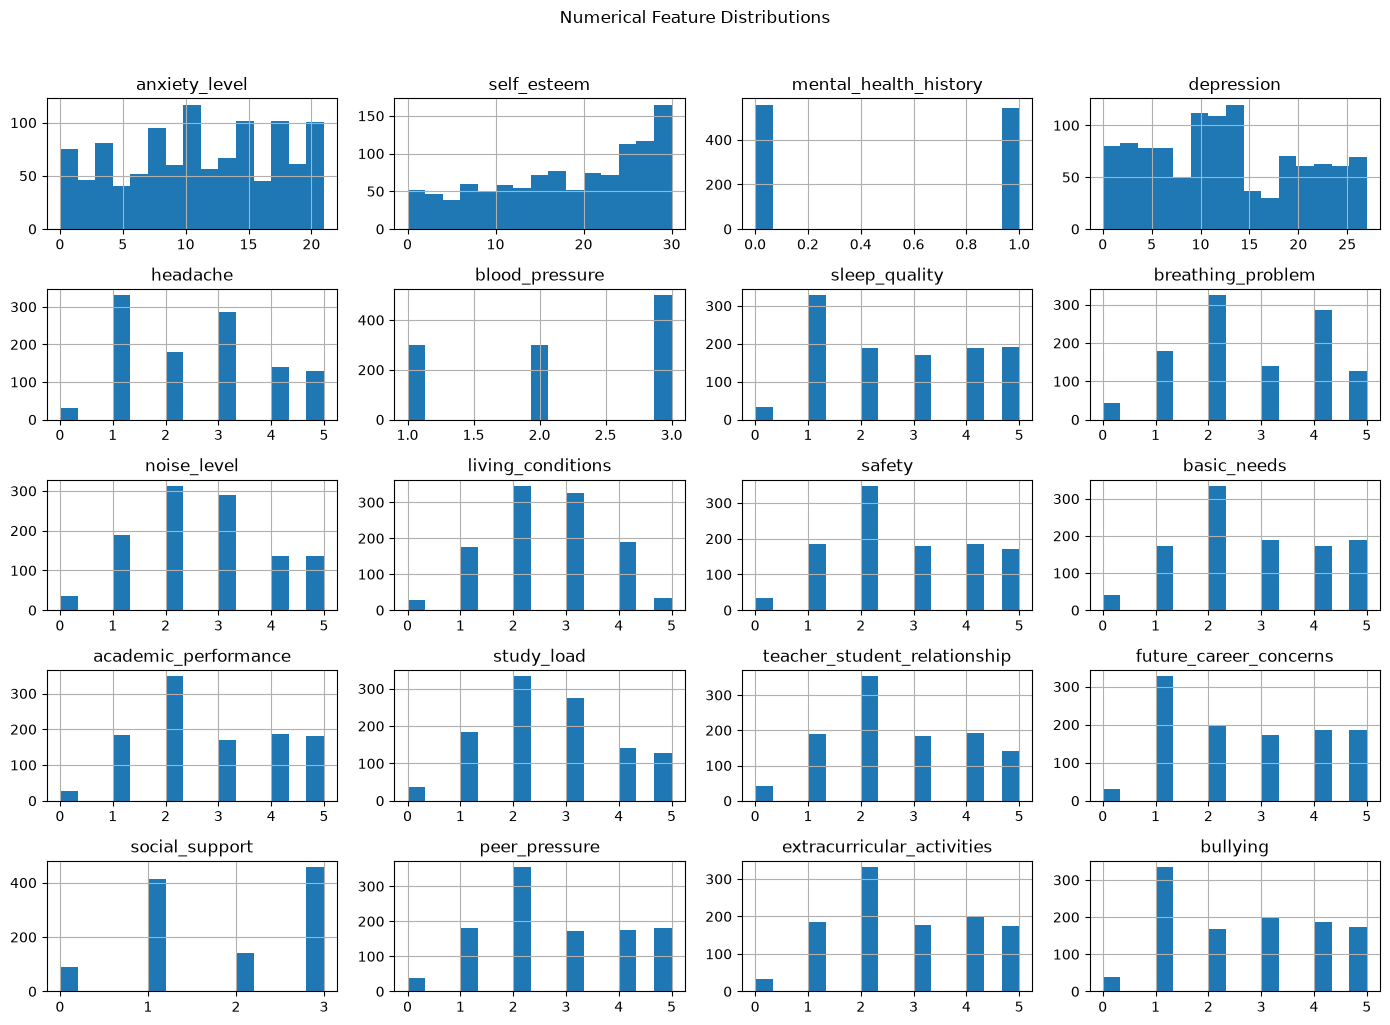

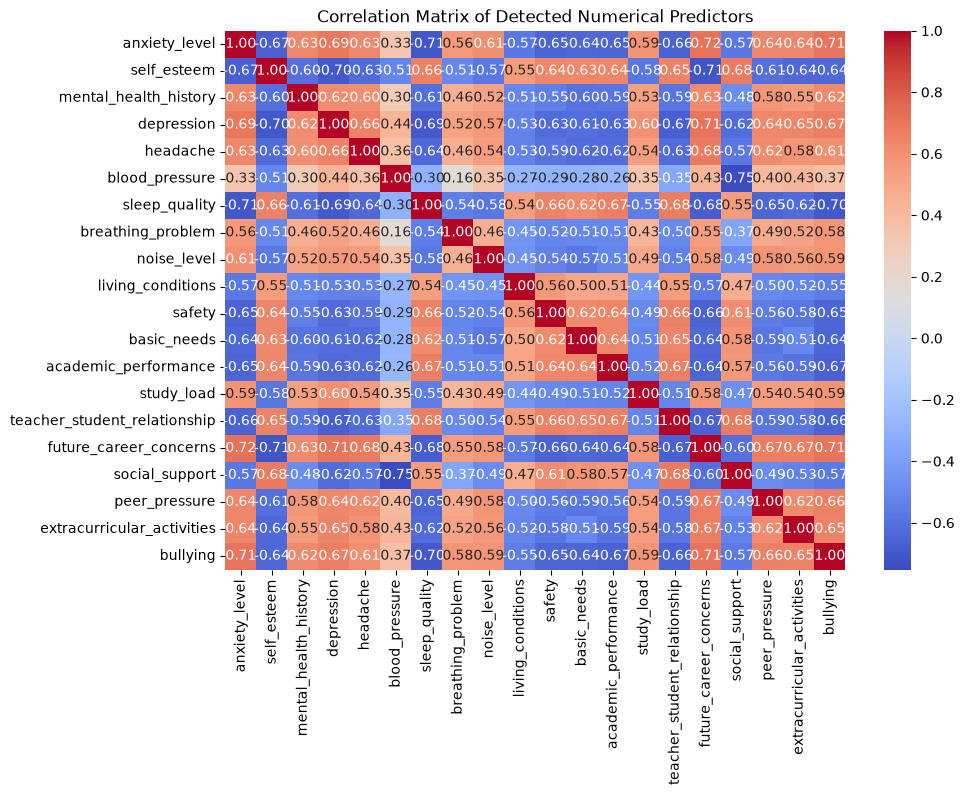

In [7]:
# Numerical columns detected by pandas
numeric_detected = df.select_dtypes(include=np.number).columns.tolist()
numeric_predictors = [c for c in numeric_detected if c != TARGET]

print("Numerical columns detected:", numeric_predictors)

if numeric_predictors:
    df[numeric_predictors].hist(figsize=(14, 10), bins=15)
    plt.suptitle("Numerical Feature Distributions", y=1.02)
    plt.tight_layout()
    plt.show()

# Correlation among numeric columns (EDA only; not used for preprocessing decisions)
if len(numeric_predictors) >= 2:
    plt.figure(figsize=(10, 7))
    sns.heatmap(df[numeric_predictors].corr(), annot=True, fmt=".2f", cmap="coolwarm")
    plt.title("Correlation Matrix of Detected Numerical Predictors")
    plt.show()

# ৮. Data Cleaning — Basic Cleaning ও Target Validation

**এই cell-এ কী হচ্ছে?**  
Target missing/invalid rows বাদ দেওয়া হবে, duplicate rows বাদ দেওয়া হবে এবং column names পরিষ্কার করা হবে।

**কেন করছি?**  
Target label impute করা উচিত নয়, কারণ response variable artificially তৈরি করলে supervised learning-এর validity ক্ষতিগ্রস্ত হতে পারে। Source paper-ও invalid/missing target record বাদ দেওয়ার preventive rule ব্যবহার করেছে। fileciteturn2file0L14-L27

**খেয়াল রাখবে:** Predictor missing values এখানে manually fill করছি না। সেগুলো পরে preprocessing pipeline-এর ভেতরে imputation হবে—এতে data leakage কমে। Source paper-ও imputation/encoding pipeline-এর মধ্যে training partitions-এ fit করেছে। fileciteturn2file0L45-L50

In [8]:
# Copy to preserve the raw loaded dataframe
data = df.copy()

# Normalize column names
data.columns = (
    data.columns.astype(str)
    .str.strip()
    .str.lower()
    .str.replace(" ", "_", regex=False)
)

TARGET = "stress_level"

# Remove rows with missing target
before_target = len(data)
data = data.dropna(subset=[TARGET]).copy()

# Remove exact duplicate rows
before_dup = len(data)
data = data.drop_duplicates().reset_index(drop=True)

print(f"Rows removed due to missing target: {before_target - len(data) + (before_dup - len(data))}")
print(f"Rows after cleaning: {len(data)}")
print(f"Duplicates remaining: {data.duplicated().sum()}")

print("\nTarget labels before encoding:")
print(sorted(data[TARGET].astype(str).unique().tolist()))

Rows removed due to missing target: 0
Rows after cleaning: 1100
Duplicates remaining: 0

Target labels before encoding:
['0', '1', '2']


# ৯. Target Encoding — Stress Level-কে Model-ready করা

**এই cell-এ কী হচ্ছে?**  
Target label-কে machine-learning model-এর জন্য numeric class label-এ encode করা হবে।

**কেন করছি?**  
Scikit-learn classifiers সাধারণত numeric target নিয়ে কাজ করে। Encoding শুধু **target**-এ হবে; predictor-এর semantic category encoding পরে pipeline-এর ভিতরে হবে।

**গুরুত্বপূর্ণ:** `stress_level` low/medium/high-এর observed categories। আমরা এটাকে causal বা latent severity scale হিসেবে দাবি করছি না। Source paper একইভাবে nominal multiclass formulation ব্যবহার করেছে। fileciteturn2file0L21-L27

In [9]:
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(data[TARGET].astype(str))

X = data.drop(columns=[TARGET]).copy()

print("Classes:", label_encoder.classes_)
print("Encoded classes:", np.unique(y))
print("X shape:", X.shape)
print("y shape:", y.shape)

Classes: ['0' '1' '2']
Encoded classes: [0 1 2]
X shape: (1100, 20)
y shape: (1100,)


# ১০. Feature Categorization — ২০টি Predictor-কে ৫টি Domain-এ ভাগ করা

**এই cell-এ কী হচ্ছে?**  
Features-কে research-এর পাঁচটি conceptual domain-এ map করা হবে:

- **Psychological**
- **Physiological**
- **Academic**
- **Social**
- **Environmental**

Source paper-এ dataset-এর 20 predictors-কে এই পাঁচটি domain-এর মধ্যে conceptualize করা হয়েছে। fileciteturn1file7L373-L387

এটি আমাদের future contribution-এর জন্য খুব গুরুত্বপূর্ণ, কারণ পরে আমরা **domain-level ablation** করব।

**Source-paper-consistent feature typing:** paper অনুযায়ী 17টি predictor categorical হিসেবে explicitly treated এবং 3টি numerical predictor রাখা হয়েছিল। fileciteturn2file0L28-L44

এই notebook-এ সেই semantic typing-এর ভিত্তিতে:
- Numerical: `anxiety_level`, `self_esteem`, `depression`
- Categorical/ordinal: বাকি 17 predictors

> যদি তোমার downloaded dataset-এর column spelling আলাদা হয়, mapping cell-এ correction করতে হবে—guess করে feature rename করা যাবে না।

In [10]:
# Source-paper-consistent conceptual domains
DOMAIN_FEATURES = {
    "psychological": [
        "anxiety_level", "self_esteem", "mental_health_history", "depression"
    ],
    "physiological": [
        "headache", "blood_pressure", "sleep_quality", "breathing_problem"
    ],
    "academic": [
        "academic_performance", "study_load", "future_career_concerns"
    ],
    "social": [
        "teacher_student_relationship", "social_support",
        "peer_pressure", "extracurricular_activities", "bullying"
    ],
    "environmental": [
        "noise_level", "living_conditions", "safety", "basic_needs"
    ],
}

# Expected semantic typing from the source paper
EXPECTED_NUMERIC = ["anxiety_level", "self_esteem", "depression"]
EXPECTED_CATEGORICAL = [
    "mental_health_history", "headache", "blood_pressure", "sleep_quality",
    "breathing_problem", "noise_level", "living_conditions", "safety",
    "basic_needs", "academic_performance", "study_load",
    "teacher_student_relationship", "future_career_concerns",
    "social_support", "peer_pressure", "extracurricular_activities", "bullying"
]

feature_cols = X.columns.tolist()

domain_flat = [f for fs in DOMAIN_FEATURES.values() for f in fs]
missing_from_dataset = sorted(set(domain_flat) - set(feature_cols))
unmapped_dataset_features = sorted(set(feature_cols) - set(domain_flat))

print("Total predictors in dataset:", len(feature_cols))
print("Features expected by domain map:", len(domain_flat))
print("Missing from dataset:", missing_from_dataset)
print("Unmapped dataset features:", unmapped_dataset_features)

if missing_from_dataset or unmapped_dataset_features:
    raise ValueError(
        "Feature mapping পুরোপুরি মেলেনি। উপরের output দেখে DOMAIN_FEATURES ঠিক করো। "
        "Guess করে mapping পরিবর্তন কোরো না।"
    )

numeric_features = [f for f in EXPECTED_NUMERIC if f in feature_cols]
categorical_features = [f for f in EXPECTED_CATEGORICAL if f in feature_cols]

print("\nNumerical features:", numeric_features)
print("Categorical/ordinal features:", categorical_features)
print("Numeric count:", len(numeric_features))
print("Categorical count:", len(categorical_features))

Total predictors in dataset: 20
Features expected by domain map: 20
Missing from dataset: []
Unmapped dataset features: []

Numerical features: ['anxiety_level', 'self_esteem', 'depression']
Categorical/ordinal features: ['mental_health_history', 'headache', 'blood_pressure', 'sleep_quality', 'breathing_problem', 'noise_level', 'living_conditions', 'safety', 'basic_needs', 'academic_performance', 'study_load', 'teacher_student_relationship', 'future_career_concerns', 'social_support', 'peer_pressure', 'extracurricular_activities', 'bullying']
Numeric count: 3
Categorical count: 17


# ১১. Domain-wise Feature Summary

**এই cell-এ কী হচ্ছে?**  
প্রতিটি domain-এ কতটি feature আছে তা দেখানো হবে।

**কেন করছি?**  
এটি শুধু documentation নয়। আমাদের proposed research-এর পরের ধাপে domain-level ablation experiment-এর foundation হিসেবে এই mapping সংরক্ষণ করা হবে।

**আজকের milestone:** Feature categorization সম্পন্ন হলে আমরা dataset-কে শুধু model input হিসেবে নয়, research question-এর domain structure হিসেবেও ব্যবহার করতে পারব।

In [11]:
domain_summary = pd.DataFrame(
    [
        {"Domain": domain.title(), "Feature Count": len(features), "Features": ", ".join(features)}
        for domain, features in DOMAIN_FEATURES.items()
    ]
)
display(domain_summary)

,Domain,Feature Count,Features
0,Psychological,4,"anxiety_level, self_esteem, mental_health_hist..."
1,Physiological,4,"headache, blood_pressure, sleep_quality, breat..."
2,Academic,3,"academic_performance, study_load, future_caree..."
3,Social,5,"teacher_student_relationship, social_support, ..."
4,Environmental,4,"noise_level, living_conditions, safety, basic_..."


# ১২. Train / Holdout Split — ৮০% Training এবং ২০% Independent Holdout

**এই cell-এ কী হচ্ছে?**  
Dataset-কে **80% training/development** এবং **20% independent holdout**-এ stratified split করা হবে।

**কেন করছি?**  
Holdout set model selection/tuning-এর সময় ব্যবহার করা যাবে না। এটি শেষে final generalization check-এর জন্য থাকবে।

Source paper-এ একইভাবে 80% training এবং 20% independent holdout ব্যবহার করা হয়েছিল এবং class distribution preserve করার জন্য stratification করা হয়েছিল। fileciteturn2file0L51-L55

এখানে `stratify=y` ব্যবহার করছি যাতে stress classes-এর proportion দুই অংশে যতটা সম্ভব একই থাকে।

In [12]:
X_train, X_holdout, y_train, y_holdout = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

print("Training shape:", X_train.shape)
print("Holdout shape:", X_holdout.shape)

train_dist = pd.Series(y_train).value_counts(normalize=True).sort_index().mul(100)
holdout_dist = pd.Series(y_holdout).value_counts(normalize=True).sort_index().mul(100)

split_summary = pd.DataFrame({
    "Train %": train_dist,
    "Holdout %": holdout_dist
})
split_summary.index = label_encoder.inverse_transform(split_summary.index.astype(int))

display(split_summary.round(2))

Training shape: (880, 20)
Holdout shape: (220, 20)


,Train %,Holdout %
0,33.98,33.64
1,32.50,32.73
2,33.52,33.64


# ১৩. Preprocessing Pipeline — Leakage Prevent করা

**এই cell-এ কী হচ্ছে?**  
Numerical এবং categorical feature-এর জন্য আলাদা preprocessing block বানানো হবে:

**Numerical**
- Median imputation
- StandardScaler

**Categorical/ordinal**
- Most-frequent imputation
- One-hot encoding
- `handle_unknown="ignore"`

তারপর এগুলো `ColumnTransformer`-এর মাধ্যমে model pipeline-এর সঙ্গে যুক্ত হবে।

**কেন করছি?**  
সব preprocessing training data থেকে শিখতে হবে। যদি পুরো dataset আগে scale/encode/impute করা হয়, তাহলে validation/holdout information training-এ leak করতে পারে।

Source paper-এও ColumnTransformer-এর মাধ্যমে numerical median imputation + standardization এবং categorical mode imputation + one-hot encoding pipeline-এর মধ্যে রাখা হয়েছে। fileciteturn2file0L45-L50

In [13]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# categorical_transformer = Pipeline(steps=[
#     ("imputer", SimpleImputer(strategy="most_frequent")),
#     ("onehot", OneHotEncoder(handle_unknown="ignore"))
# ])


categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

print("Preprocessing pipeline created.")
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

Preprocessing pipeline created.
Numeric features: ['anxiety_level', 'self_esteem', 'depression']
Categorical features: ['mental_health_history', 'headache', 'blood_pressure', 'sleep_quality', 'breathing_problem', 'noise_level', 'living_conditions', 'safety', 'basic_needs', 'academic_performance', 'study_load', 'teacher_student_relationship', 'future_career_concerns', 'social_support', 'peer_pressure', 'extracurricular_activities', 'bullying']


# ১৪. Baseline Model — প্রথম Reference Model

**এই cell-এ কী হচ্ছে?**  
একটি simple **Logistic Regression** baseline তৈরি করা হবে।

**কেন করছি?**  
Research-এ baseline দরকার, যাতে পরের tree/ensemble model-এর performance meaningfulভাবে compare করা যায়। Baseline model খুব complex না রেখে একটি interpretable linear reference রাখা হয়েছে।

এটি source paper-এর final best model claim নয়। Source paper 9টি ensemble/boosting algorithm compare করেছে এবং Gradient Boosting-এর mean F1-weighted score সর্বোচ্চ ছিল। fileciteturn2file5L273-L286

আমাদের notebook-এ baseline independently run হবে।

In [14]:
baseline_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=RANDOM_STATE
    ))
])

baseline_model.fit(X_train, y_train)

baseline_pred = baseline_model.predict(X_holdout)

baseline_results = {
    "Model": "Logistic Regression (Baseline)",
    "Accuracy": accuracy_score(y_holdout, baseline_pred),
    "Balanced Accuracy": balanced_accuracy_score(y_holdout, baseline_pred),
    "F1-weighted": f1_score(y_holdout, baseline_pred, average="weighted"),
    "F1-macro": f1_score(y_holdout, baseline_pred, average="macro"),
    "MCC": matthews_corrcoef(y_holdout, baseline_pred)
}

display(pd.DataFrame([baseline_results]).round(4))

print(classification_report(
    y_holdout,
    baseline_pred,
    target_names=label_encoder.classes_,
    zero_division=0
))

,Model,Accuracy,Balanced Accuracy,F1-weighted,F1-macro,MCC
0,Logistic Regression (Baseline),0.8818,0.8823,0.8812,0.8815,0.824


              precision    recall  f1-score   support

           0       0.91      0.81      0.86        74
           1       0.89      0.93      0.91        72
           2       0.85      0.91      0.88        74

    accuracy                           0.88       220
   macro avg       0.88      0.88      0.88       220
weighted avg       0.88      0.88      0.88       220



MCC = Matthews Correlation Coefficient
এটা prediction আর actual class-এর মধ্যে overall correlation/agreement measure করে।

Precision কী?

Model যাদের High stress বলেছে, তাদের মধ্যে আসলে কতজন High?

Recall কী?

আসলেই যারা High stress ছিল, তাদের মধ্যে model কতজনকে High হিসেবে ধরতে পেরেছে?

F1 এই দুইটার balance।

# ১৫. Model Validation — একাধিক Model-এর Cross-Validation Comparison

**এই cell-এ কী হচ্ছে?**  
Training set-এর মধ্যে **Stratified 5-Fold Cross-Validation** দিয়ে কয়েকটি candidate model compare করা হবে।

Models:
- Logistic Regression
- Random Forest
- Extra Trees
- Gradient Boosting
- HistGradientBoosting
- AdaBoost

**কেন করছি?**  
শুধু একবার train/test result দেখে best model নির্বাচন করলে split-specific result হওয়ার ঝুঁকি থাকে। Cross-validation-এ training data-এর একাধিক partition-এ performance দেখা যায়।

Source paper আরও rigorous nested CV ব্যবহার করেছে—outer 10-fold এবং inner 3-fold tuning। fileciteturn2file0L434-L451  
**আজকের notebook-এর এই checkpoint-এ আমরা প্রথমে reproducible model screening করছি।** পরে final research version-এ nested CV/tuning যোগ করা হবে।

In [15]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
    "HistGradientBoosting": HistGradientBoostingClassifier(random_state=RANDOM_STATE),
    "AdaBoost": AdaBoostClassifier(random_state=RANDOM_STATE)
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

scoring = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "f1_weighted": "f1_weighted",
    "f1_macro": "f1_macro"
}

cv_rows = []

for name, estimator in models.items():
    pipe = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", estimator)
    ])

    scores = cross_validate(
        pipe,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        return_train_score=False
    )

    cv_rows.append({
        "Model": name,
        "CV Accuracy Mean": scores["test_accuracy"].mean(),
        "CV Accuracy SD": scores["test_accuracy"].std(),
        "CV Balanced Accuracy Mean": scores["test_balanced_accuracy"].mean(),
        "CV F1-weighted Mean": scores["test_f1_weighted"].mean(),
        "CV F1-weighted SD": scores["test_f1_weighted"].std(),
        "CV F1-macro Mean": scores["test_f1_macro"].mean()
    })

cv_results = (
    pd.DataFrame(cv_rows)
    .sort_values("CV F1-weighted Mean", ascending=False)
    .reset_index(drop=True)
)

display(cv_results.round(4))

,Model,CV Accuracy Mean,CV Accuracy SD,CV Balanced Accuracy Mean,CV F1-weighted Mean,CV F1-weighted SD,CV F1-macro Mean
0,AdaBoost,0.8909,0.0340,0.8909,0.8909,0.0341,0.8909
1,Logistic Regression,0.8864,0.0287,0.8863,0.8863,0.0289,0.8863
2,Extra Trees,0.8841,0.0300,0.8840,0.8844,0.0301,0.8844
3,Random Forest,0.8830,0.0261,0.8831,0.8829,0.0262,0.8830
4,Gradient Boosting,0.8773,0.0258,0.8772,0.8772,0.0256,0.8770
5,HistGradientBoosting,0.8705,0.0320,0.8704,0.8705,0.0319,0.8705


# ১৬. Best Model Selection — Predefined Criterion

**এই cell-এ কী হচ্ছে?**  
Candidate models-কে **mean CV F1-weighted** অনুযায়ী rank করা হবে।

**কেন F1-weighted?**  
এটি multiclass classification-এ class frequency বিবেচনা করে এবং source paper-ও model selection-এর primary criterion হিসেবে F1-weighted ব্যবহার করেছে। fileciteturn2file0L460-L463

**Important:**  
এই stage-এ “best” মানে **এই experiment-এর predefined metric অনুযায়ী best**, absolute বা universally superior model নয়। Source paper-এও Gradient Boosting highest mean F1 পেলেও Friedman test statistically significant model difference দেখায়নি। fileciteturn1file4L210-L225

In [16]:
best_model_name = cv_results.loc[0, "Model"]
best_estimator = models[best_model_name]

best_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", best_estimator)
])

best_pipeline.fit(X_train, y_train)

holdout_pred = best_pipeline.predict(X_holdout)

best_holdout_results = {
    "Model": best_model_name,
    "Holdout Accuracy": accuracy_score(y_holdout, holdout_pred),
    "Holdout Balanced Accuracy": balanced_accuracy_score(y_holdout, holdout_pred),
    "Holdout F1-weighted": f1_score(y_holdout, holdout_pred, average="weighted"),
    "Holdout F1-macro": f1_score(y_holdout, holdout_pred, average="macro"),
    "Holdout MCC": matthews_corrcoef(y_holdout, holdout_pred)
}

print("Selected best model:", best_model_name)
display(pd.DataFrame([best_holdout_results]).round(4))

print("\nClassification report:")
print(classification_report(
    y_holdout,
    holdout_pred,
    target_names=label_encoder.classes_,
    zero_division=0
))

Selected best model: AdaBoost


,Model,Holdout Accuracy,Holdout Balanced Accuracy,Holdout F1-weighted,Holdout F1-macro,Holdout MCC
0,AdaBoost,0.8909,0.8913,0.8908,0.891,0.8384



Classification report:
              precision    recall  f1-score   support

           0       0.95      0.82      0.88        74
           1       0.89      0.93      0.91        72
           2       0.84      0.92      0.88        74

    accuracy                           0.89       220
   macro avg       0.90      0.89      0.89       220
weighted avg       0.90      0.89      0.89       220



# ১৭. Baseline বনাম Best Model — Initial Checkpoint

**এই cell-এ কী হচ্ছে?**  
Baseline Logistic Regression এবং CV-selected best model-এর holdout performance পাশাপাশি দেখা হবে।

**কেন করছি?**  
এতে বোঝা যাবে complex candidate model baseline-এর তুলনায় বাস্তবে improvement দিয়েছে কি না।

**আজকের research milestone এখানেই শেষ:**  
আমরা এখন পর্যন্ত dataset → cleaning → feature domains → leakage-controlled preprocessing → baseline → validation → best model পর্যন্ত pipeline তৈরি করেছি।

**এর পরের research work:**  
1. Nested CV + hyperparameter tuning  
2. Domain-level ablation  
3. SHAP/global-local explainability  
4. Counterfactual analysis  
5. Statistical comparison  
6. Final interpretation and contribution

In [17]:
comparison = pd.DataFrame([
    baseline_results,
    {
        "Model": best_model_name,
        "Accuracy": best_holdout_results["Holdout Accuracy"],
        "Balanced Accuracy": best_holdout_results["Holdout Balanced Accuracy"],
        "F1-weighted": best_holdout_results["Holdout F1-weighted"],
        "F1-macro": best_holdout_results["Holdout F1-macro"],
        "MCC": best_holdout_results["Holdout MCC"]
    }
])

display(comparison.round(4))

print("\nNEXT RESEARCH MODULES")
print("1. Nested Cross-Validation + Hyperparameter Tuning")
print("2. Domain-Level Ablation Study")
print("3. SHAP Explainability")
print("4. Counterfactual / What-if Analysis")
print("5. Statistical Testing")
print("6. Final Research Findings")

,Model,Accuracy,Balanced Accuracy,F1-weighted,F1-macro,MCC
0,Logistic Regression (Baseline),0.8818,0.8823,0.8812,0.8815,0.8240
1,AdaBoost,0.8909,0.8913,0.8908,0.8910,0.8384



NEXT RESEARCH MODULES
1. Nested Cross-Validation + Hyperparameter Tuning
2. Domain-Level Ablation Study
3. SHAP Explainability
4. Counterfactual / What-if Analysis
5. Statistical Testing
6. Final Research Findings
